Johannes Standhal og Rozalia Ciupka

# CA5

### Imports

In [1]:
# Data handling
import numpy as np
import pandas as pd

# Visualisation
import seaborn as sns
import matplotlib.pyplot as plt

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Pipelines and dimension reduction
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

# Models
from sklearn.linear_model import LinearRegression

# Model selection
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score

# Evaluation
from sklearn.metrics import mean_squared_error

### Reading data

In [2]:
df_train = pd.read_csv("train.csv")
df_submission = pd.read_csv("test.csv")

### Data exploration and visualisation

In [3]:
df_train.info()

categorical = ['smoking_status']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367500 entries, 0 to 367499
Data columns (total 17 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            367500 non-null  int64  
 1   age                           345653 non-null  float64
 2   sleep_duration_hrs            340323 non-null  float64
 3   sleep_quality_score           357702 non-null  float64
 4   cardio_mins_wk                355386 non-null  float64
 5   water_intake_liters           358969 non-null  float64
 6   screen_time_recreational_hrs  338865 non-null  float64
 7   social_media_hrs              362207 non-null  float64
 8   blood_pressure_sys            357789 non-null  float64
 9   diet_ultra_processed_pct      354171 non-null  float64
 10  diet_omega3_freq              344987 non-null  float64
 11  smoking_status                342146 non-null  object 
 12  alcohol_drinks_wk             346938 non-nul

In [4]:
# Check for missing values, we have none
print(f"missing values in training data: {df_train.isna().sum()}")

missing values in training data: id                                  0
age                             21847
sleep_duration_hrs              27177
sleep_quality_score              9798
cardio_mins_wk                  12114
water_intake_liters              8531
screen_time_recreational_hrs    28635
social_media_hrs                 5293
blood_pressure_sys               9711
diet_ultra_processed_pct        13329
diet_omega3_freq                22513
smoking_status                  25354
alcohol_drinks_wk               20562
novel_learning_hrs_wk           26727
social_connection_score         24873
chronic_stress_score            17929
target                              0
dtype: int64


In [5]:
df_train = df_train.dropna(axis=0)

In [6]:
# Check for duplicate rows, we have none
print("Duplicate rows:", df_train.duplicated().sum())

Duplicate rows: 0


In [7]:
# Class distribution in the training data
print(df_train["target"].value_counts(normalize=True))

df_train = df_train.drop(['id', 'target'], axis=1)

target
30    0.227644
28    0.200440
27    0.177360
29    0.167012
26    0.120529
25    0.062810
24    0.027103
23    0.010313
22    0.004129
21    0.001574
20    0.000746
19    0.000241
18    0.000088
17    0.000012
Name: proportion, dtype: float64


Text(0.5, 1.0, 'Correlation map from training data')

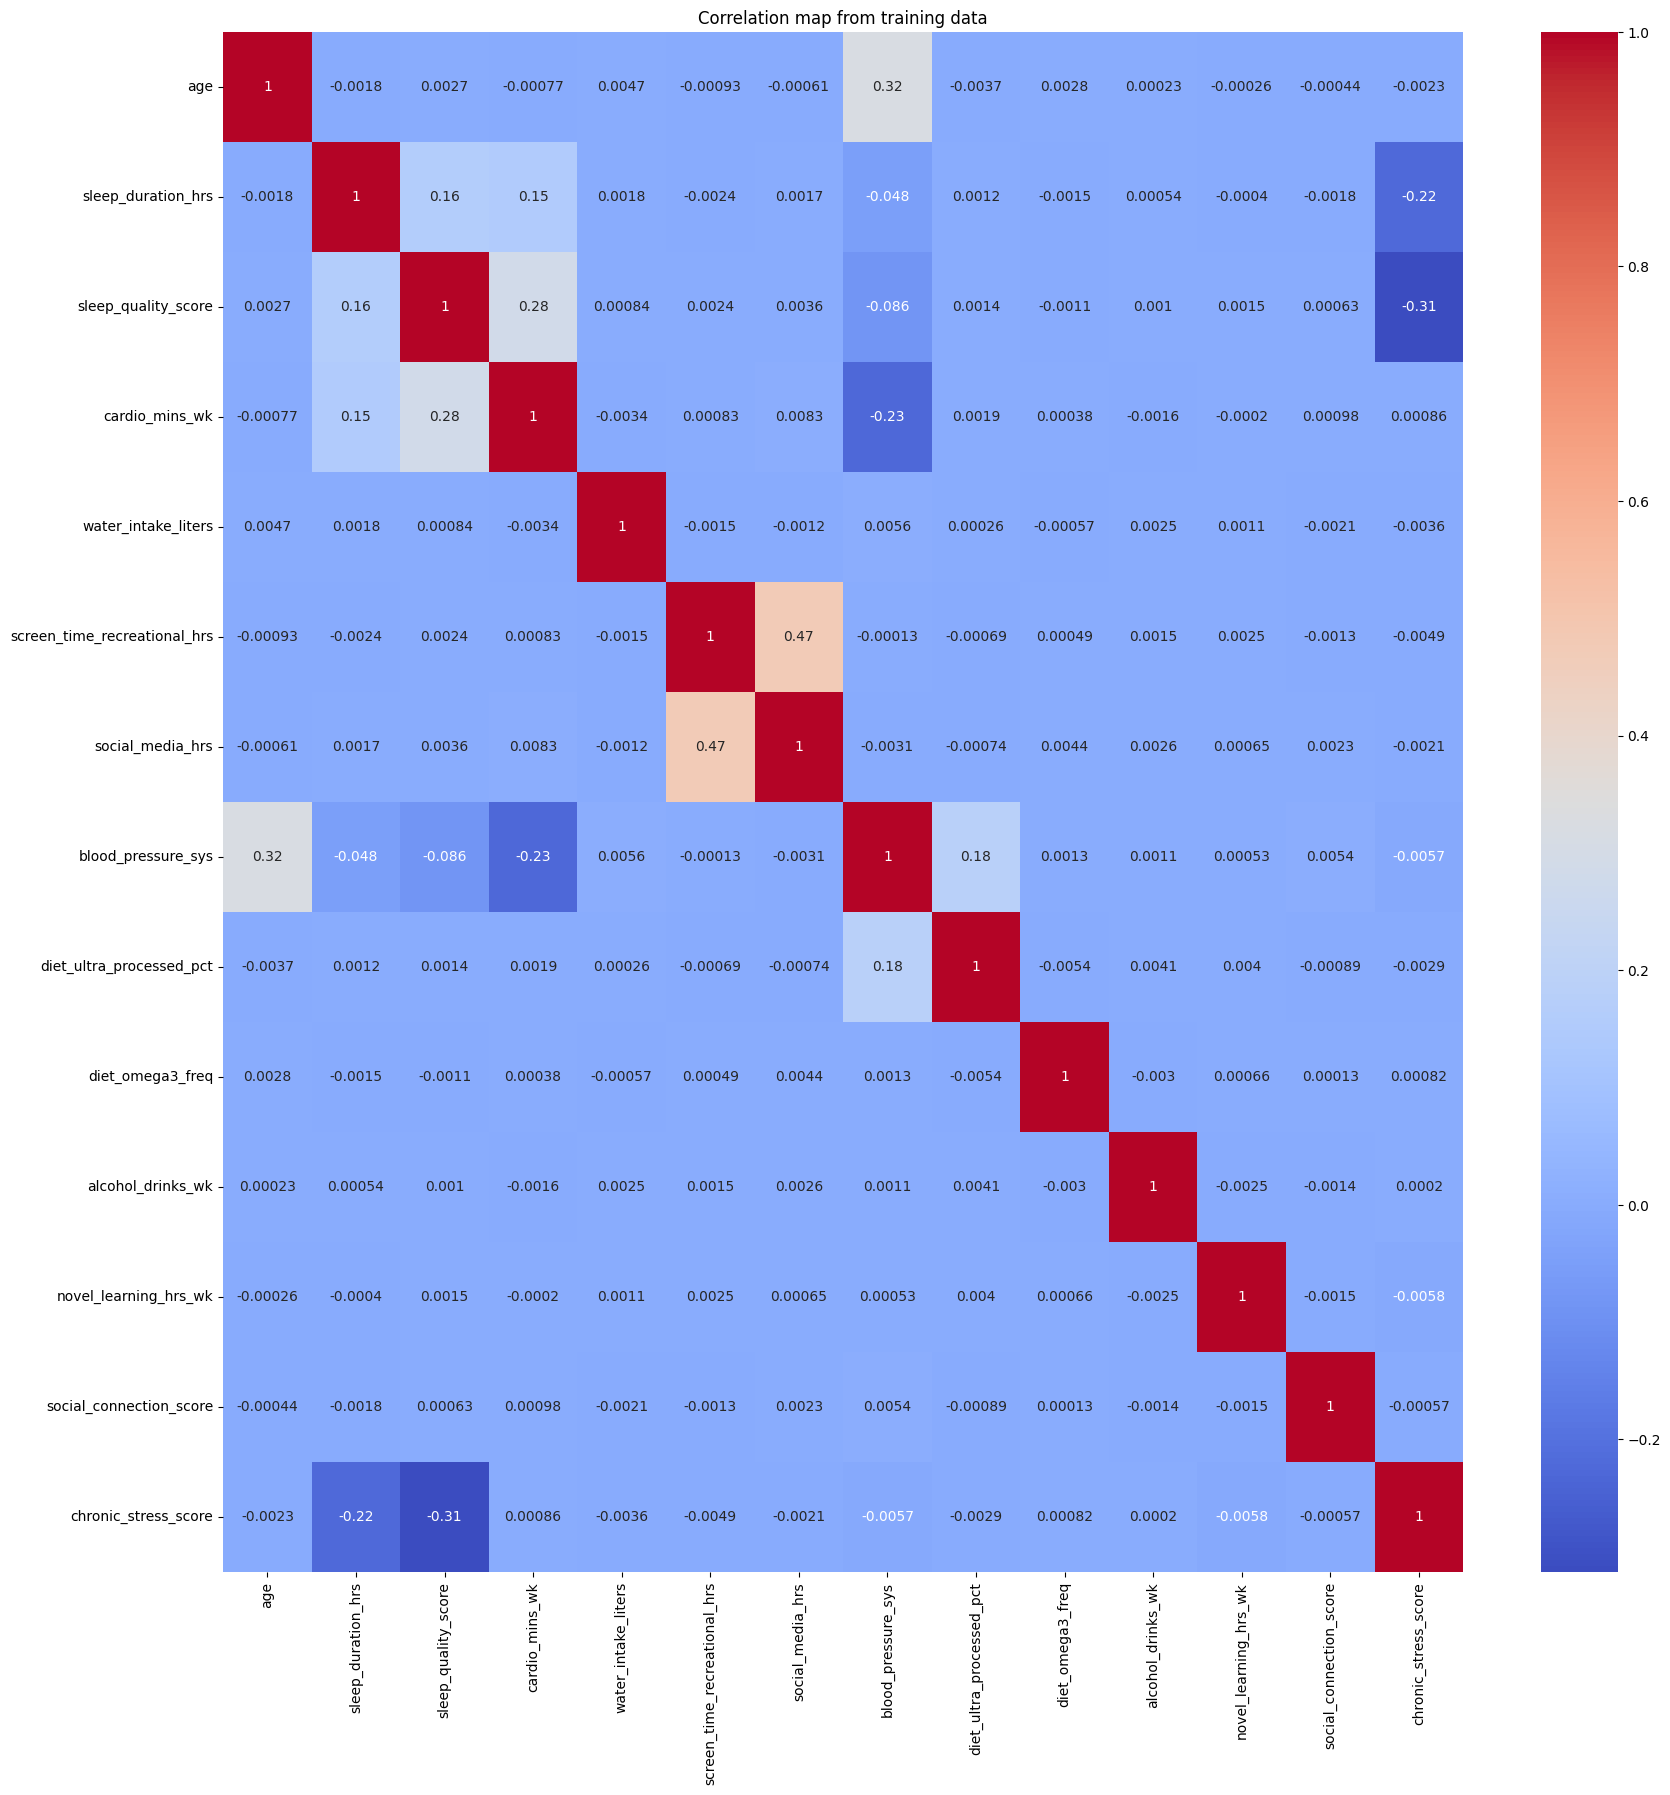

In [8]:
# creating a new dataframe with only numerical features for correlation map and whisker plots
df_numeric = df_train.drop(columns=categorical)

# correlation map from numerical features, modified code from lecture 12
plt.figure(figsize=(20,20))
sns.heatmap(df_numeric.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation map from training data")

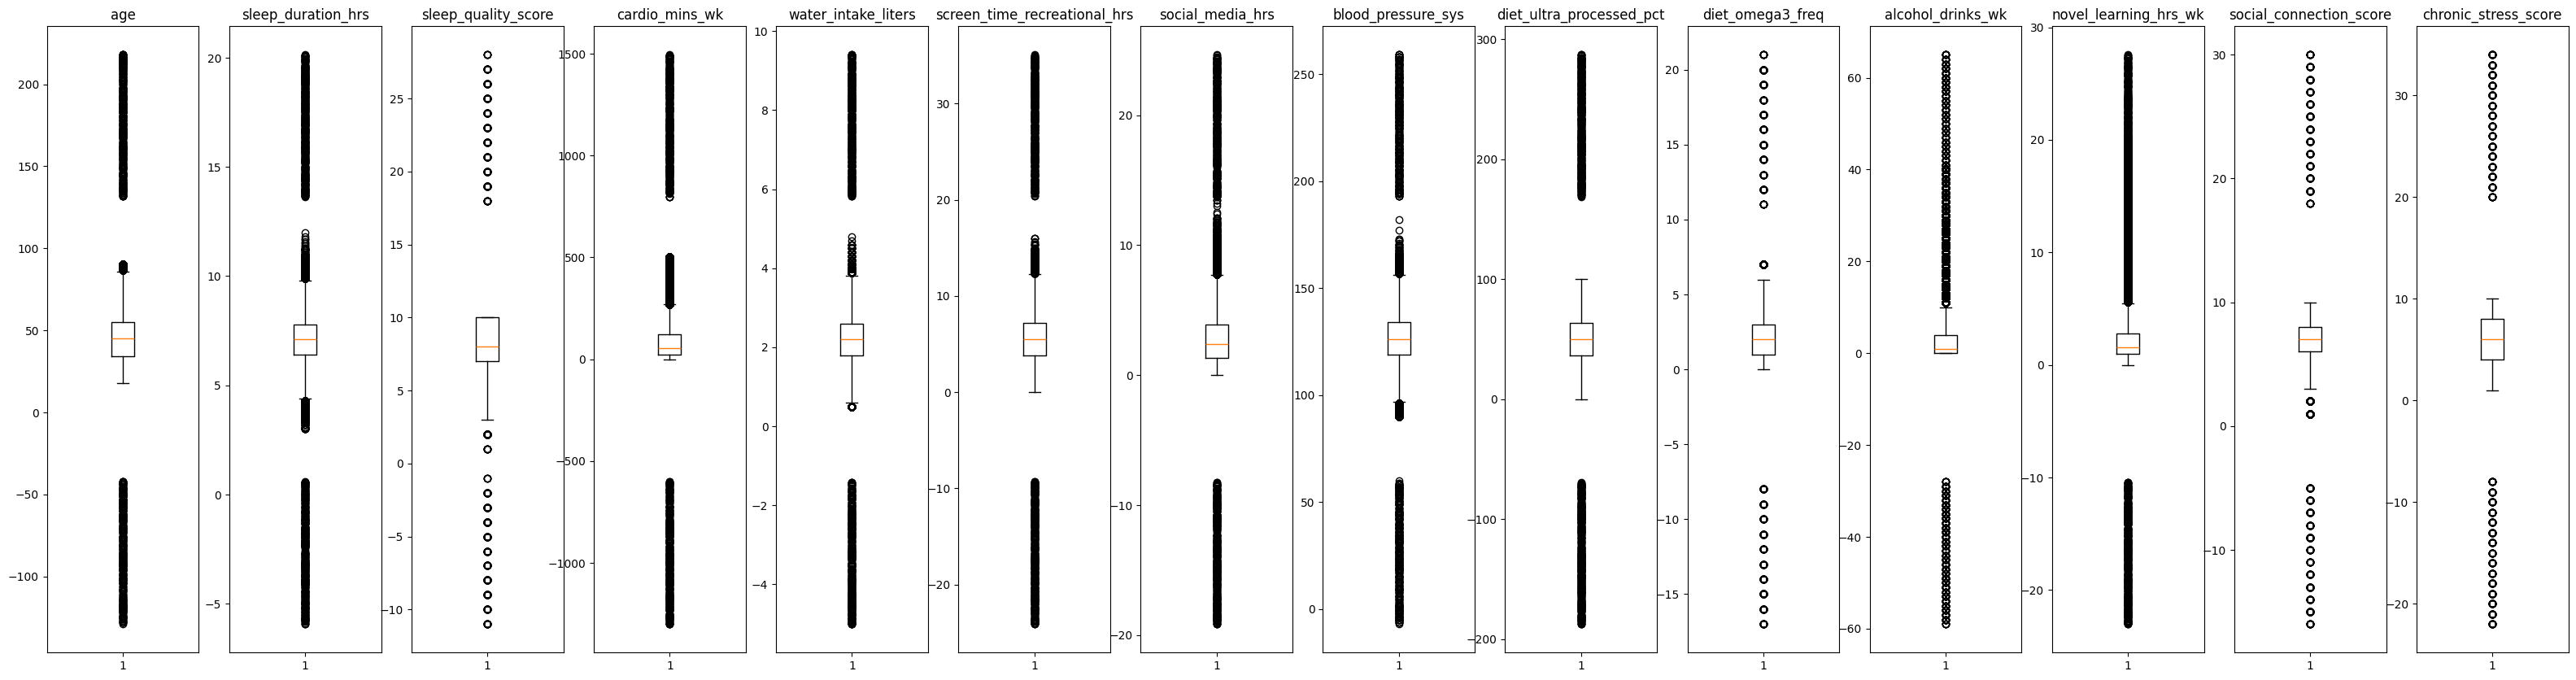

In [9]:
# whisker plots to check for outliers, modified code from lecture 12
fig, ax = plt.subplots(1, len(df_numeric.columns), figsize=(40,10))

for i, column in enumerate(df_numeric.columns):
    ax[i].set_title(column)
    ax[i].boxplot(df_numeric[column])

### Data preprocessing and visualisation

In [10]:
df_train = pd.read_csv('train.csv')

df_train = df_train.dropna(axis=0)

x_train = df_train.drop(columns=["target", "id"])
y_train = df_train["target"]

X_train, X_test, Y_train, Y_test = train_test_split(x_train, y_train, test_size=0.4, random_state=42, stratify=y_train) 

In [11]:
# Naming the columns with categorical data for preprocessing 
# (redoing this as we dropped some features)
categorical_features = [
    "smoking_status"
]

# Getting the columns with numerical data for preprocessing
numerical_features = []
for col in X_train.columns:
    if col not in categorical_features:
        numerical_features.append(col)


# Numerical preprocessing
numerical_pipeline = Pipeline([
    # We dont have any missing data, but adding imputer for robustness as mentioned in the lecture
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Numerical preprocessing with no scaling
numerical_pipeline_no_scaling = Pipeline([
    # Some models dont require scaling
    ('imputer', SimpleImputer(strategy='median')),
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    # One hot encoding because we have no ordinal features
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

In [12]:
# Preproccesor
preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, numerical_features),
    ('categorical', categorical_pipeline, categorical_features)
])

# Preproccesor without scaling
preprocessor_no_scaling = ColumnTransformer([
    ('numerical', numerical_pipeline_no_scaling, numerical_features),
    ('categorical', categorical_pipeline, categorical_features)
])

### Modelling

In [13]:
# PCR
cv = KFold(n_splits=5, shuffle=True, random_state=42)

PCR_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LinearRegression())
])

# Apply pipeline to grid search with cross-validation
PCR_scores = cross_val_score(
    PCR_pipeline,
    X_train,
    Y_train,
    cv=cv,
    scoring='neg_mean_squared_error'
)

PCR_score_train = np.mean(PCR_scores)

print(PCR_score_train*(-1))

1.994348854486154


### Final evaluation

### Kaggle submission